# Etapa 6 — Janelas móveis (regressão limpa)

A etapa 5 deu **um** número para 2009–2026: 63% de peso externo no explicado. Mas o período
mistura fases muito diferentes (pós-2008, crise de 2015–2018, Covid...). Aqui repetimos a
**regressão limpa da etapa 5 em cada janela** de N meses, deslizando 1 mês por vez:

```
Janela 1:   jan/2009 ──────────── dez/2013   → peso externo = ?
Janela 2:     fev/2009 ──────────── jan/2014   → peso externo = ?
   ...
Última:                       nov/2021 ──────────── out/2026 → peso externo = ?
```

- Janela principal: **60 meses** (5 anos); robustez: **84 meses** (7 anos).
- Em cada janela, as domésticas são limpas **com os dados daquela janela**.
- Cada resultado é datado no **fim da janela** ("peso nos N meses até esta data").

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

dados = pd.read_csv("dados/tratados/variacoes_mensais.csv", index_col=0, parse_dates=True)

EXTERNAS = ["d_ust10", "dl_vix", "dl_dolar"]
DOMESTICAS = ["d_selic", "d_primario", "dl_cds"]
Y = "dl_cambio"

## 1. O que é calculado em cada janela

Exatamente a etapa 5, aplicada a um pedaço da amostra:
1. regredir cada doméstica nas externas e guardar o resíduo (parte doméstica);
2. R² do câmbio só com as externas → **externo**;
3. R² do câmbio só com os resíduos → **doméstico** (sem sobreposição, por construção);
4. o que sobra → **não explicado**.

In [2]:
def pesos_regressao(janela):
    X_ext = sm.add_constant(janela[EXTERNAS])
    dom_limpas = pd.DataFrame({d: sm.OLS(janela[d], X_ext).fit().resid for d in DOMESTICAS})
    r2_ext = sm.OLS(janela[Y], X_ext).fit().rsquared
    r2_dom = sm.OLS(janela[Y], sm.add_constant(dom_limpas)).fit().rsquared
    return {"externo": r2_ext, "doméstico": r2_dom, "não explicado": 1 - r2_ext - r2_dom}


def rolar(N):
    resultados = {}
    for i in range(len(dados) - N + 1):
        janela = dados.iloc[i : i + N]           # N meses a partir da posição i
        resultados[janela.index[-1]] = pesos_regressao(janela)
    saida = pd.DataFrame(resultados).T
    saida["externo / explicado"] = saida["externo"] / (saida["externo"] + saida["doméstico"])
    return saida

reg60 = rolar(60)
reg84 = rolar(84)
print(f"Janelas de 60 meses: {len(reg60)}  ({reg60.index[0]:%m/%Y} → {reg60.index[-1]:%m/%Y})")
print(f"Janelas de 84 meses: {len(reg84)}  ({reg84.index[0]:%m/%Y} → {reg84.index[-1]:%m/%Y})")

Janelas de 60 meses: 155  (12/2013 → 10/2026)
Janelas de 84 meses: 131  (12/2015 → 10/2026)


## 2. Composição ao longo do tempo (janela de 60 meses)

Leia a **altura** de cada faixa: azul = externo, laranja = doméstico, cinza = não explicado.
O topo da faixa laranja = quanto o modelo explica naquela janela (o R²).

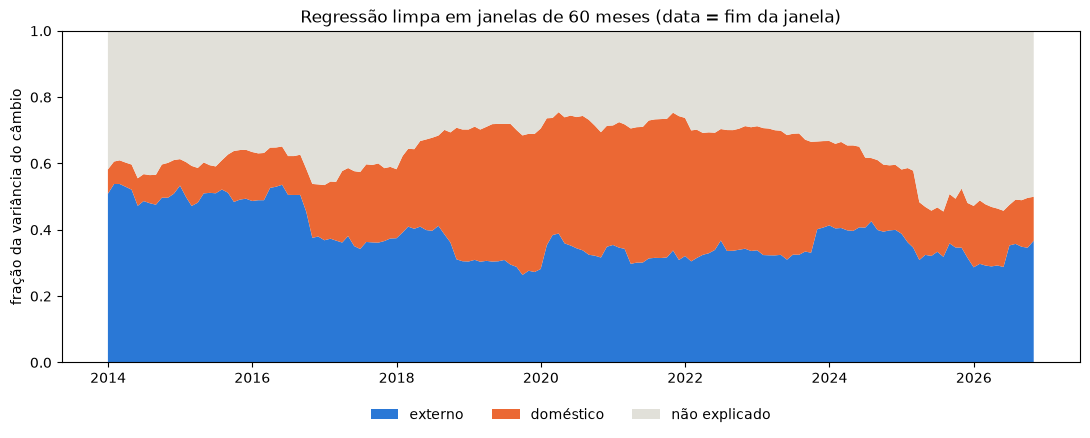

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stackplot(reg60.index, reg60["externo"], reg60["doméstico"], reg60["não explicado"],
             labels=["externo", "doméstico", "não explicado"],
             colors=["#2a78d6", "#eb6834", "#e1e0d9"])
ax.set_ylim(0, 1)
ax.set_ylabel("fração da variância do câmbio")
ax.set_title("Regressão limpa em janelas de 60 meses (data = fim da janela)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

## 3. Peso externo no explicado — e a armadilha das janelas

Linha sólida cinza = episódio **entra** na janela de 60 meses; pontilhada = episódio **sai** (60 meses
depois). Um salto na linha pode vir de um episódio saindo, e não de algo que aconteceu naquela data.

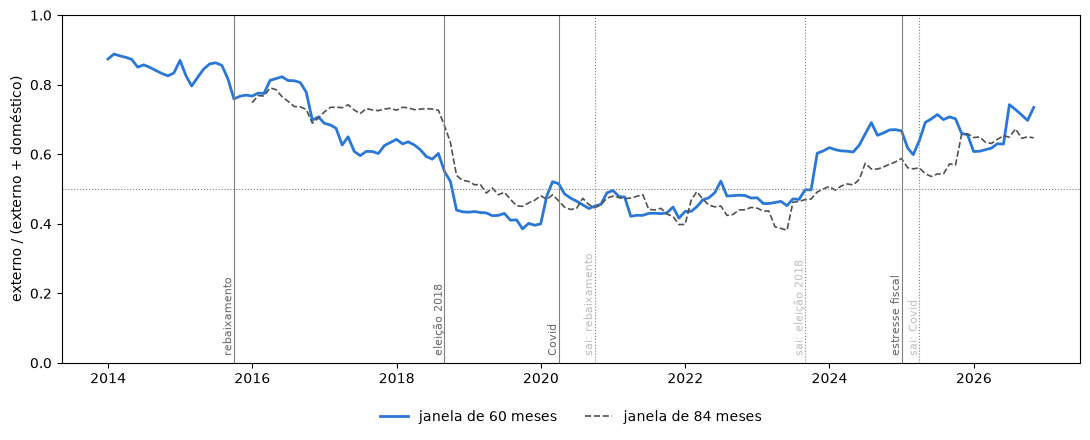

In [4]:
episodios = {"2015-09-30": "rebaixamento", "2018-08-31": "eleição 2018",
             "2020-03-31": "Covid", "2024-12-31": "estresse fiscal"}

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(reg60.index, reg60["externo / explicado"], color="#2a78d6", lw=2, label="janela de 60 meses")
ax.plot(reg84.index, reg84["externo / explicado"], color="#52514e", lw=1.2, ls="--", label="janela de 84 meses")
ax.axhline(0.5, color="gray", lw=0.8, ls=":")
for data, nome in episodios.items():
    entra = pd.Timestamp(data)
    sai = entra + pd.DateOffset(months=60)
    ax.axvline(entra, color="gray", lw=0.8)
    ax.text(entra, 0.02, nome, fontsize=8, rotation=90, va="bottom", ha="right", color="dimgray")
    if sai <= reg60.index[-1]:
        ax.axvline(sai, color="gray", lw=0.8, ls=":")
        ax.text(sai, 0.02, f"sai: {nome}", fontsize=8, rotation=90, va="bottom", ha="right", color="silver")
ax.set_ylim(0, 1)
ax.set_ylabel("externo / (externo + doméstico)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

## 4. Números

In [5]:
def resumo(serie):
    return {"média": serie.mean(), "mínimo": serie.min(), "quando (mín.)": f"{serie.idxmin():%m/%Y}",
            "máximo": serie.max(), "quando (máx.)": f"{serie.idxmax():%m/%Y}"}

pd.DataFrame({"60 meses": resumo(reg60["externo / explicado"]),
              "84 meses": resumo(reg84["externo / explicado"])}).T

,média,mínimo,quando (mín.),máximo,quando (máx.)
60 meses,0.610389,0.385432,09/2019,0.888148,01/2014
84 meses,0.564245,0.381399,05/2023,0.79068,03/2016


In [6]:
# Maiores saltos mês a mês: o que entrou e o que saiu da janela?
salto = reg60["externo / explicado"].diff().dropna()
linhas = []
for data in salto.abs().sort_values(ascending=False).head(5).index:
    saiu = (data - pd.DateOffset(months=60)) + pd.offsets.MonthEnd(0)
    linhas.append({"fim da janela": f"{data:%m/%Y}", "salto": round(salto[data], 3),
                   "entrou (câmbio, %)": round(dados.loc[data, Y], 1), "mês que saiu": f"{saiu:%m/%Y}",
                   "saiu (câmbio, %)": round(dados.loc[saiu, Y], 1)})
pd.DataFrame(linhas)

,fim da janela,salto,"entrou (câmbio, %)",mês que saiu,"saiu (câmbio, %)"
0,06/2026,0.113,2.3,06/2021,-4.5
1,10/2023,0.106,1.0,10/2018,-7.4
2,10/2018,-0.083,-7.4,10/2013,-1.2
3,01/2020,0.081,5.8,01/2015,0.2
4,10/2016,-0.081,-2.0,10/2011,-9.4


In [7]:
reg60.to_csv("resultados/etapa6_regressao_janela60.csv")
reg84.to_csv("resultados/etapa6_regressao_janela84.csv")

## O que conferir

- A média das janelas fica perto dos **63%** da amostra completa?
- As janelas de 60 e 84 meses contam a mesma história (a de 84 mais suave e mais lenta)?
- Os maiores saltos coincidem com **entradas e saídas** de episódios?